# Inversión independiente y conjunta

**Nivel 2 — Análisis aplicado**  
**Prerrequisitos:** nivel 1 y arreglos/logaritmos; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

Ambos modelos 3D son sintéticos y sus recibos guardan coordenadas y métricas por método.

## Método

Sean `dg=Ggρ+εg` y `dm=Gmκ+εm`. Inversiones independientes minimizan términos ponderados y regularizadores separados; la conjunta añade `λx||∇ρ×∇κ||²`. La escala importa porque propiedades y sensibilidades difieren. Compare RMSE por propiedad contra verdad y WRMS de ambas observaciones, conservando malla/datos. En JOINT_SHARED RMSE de densidad pasa de 0,1717462 a 0,1724129 g/cm³ (razón 1,0039), mientras RMSE magnético cambia 0,0114970 a 0,0114589 (razón 0,9967). Una mejora pequeña en una propiedad y empeoramiento en otra no prueba ventaja general. Grafique valores y calcule razones desde métricas almacenadas; este caso no establece beneficio poblacional.

Los operadores tienen unidades, cobertura y espacios nulos diferentes. El término cruzado depende de discretización y escala; gradientes paralelos no implican amplitudes iguales ni geología compartida siempre. Compare predicciones de ambos levantamientos además del error contra verdad. Revise unidades y máscaras antes de interpretar razones pequeñas.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Compare the shared case’s saved property RMSE and survey WRMS.
import json
from pathlib import Path
d=json.loads((root/"data/derived/v2/JOINT_SHARED/regularization.json").read_text(encoding="utf-8")); a=d["methods"]["joint-uncoupled"]["metrics"]; j=d["methods"]["joint"]["metrics"]
print("density RMSE g/cm³",a["model_rmse"],j["model_rmse"],"ratio",j["model_rmse"]/a["model_rmse"]); print("magnetic model RMSE",a["magnetic_model_rmse"],j["magnetic_model_rmse"],"ratio",j["magnetic_model_rmse"]/a["magnetic_model_rmse"]); print("gravity/magnetic WRMS",a["wrms"],j["wrms"],a["magnetic_wrms"],j["magnetic_wrms"])

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
density RMSE g/cm³ 0.1716494 0.1723621 ratio 1.0041520681109284
magnetic model RMSE 0.0114825 0.01145574 ratio 0.9976694970607447
gravity/magnetic WRMS 1.0 1.088985 1.0 1.005056


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

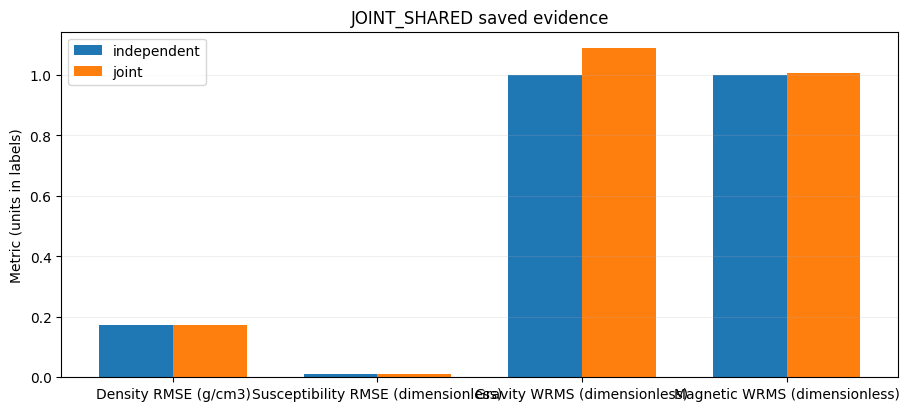

joint/independent ratios [1.00415207 0.9976695  1.088985   1.005056  ]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Plot independent and joint property errors and data misfit with units.
import matplotlib.pyplot as plt
labels=["Density RMSE (g/cm3)","Susceptibility RMSE (dimensionless)","Gravity WRMS (dimensionless)","Magnetic WRMS (dimensionless)"]; A=[a["model_rmse"],a["magnetic_model_rmse"],a["wrms"],a["magnetic_wrms"]]; J=[j["model_rmse"],j["magnetic_model_rmse"],j["wrms"],j["magnetic_wrms"]]; x=np.arange(4); fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True); ax.bar(x-.18,A,.36,label="independent"); ax.bar(x+.18,J,.36,label="joint"); ax.set(xticks=x,xticklabels=labels,ylabel="Metric (units in labels)",title="JOINT_SHARED saved evidence"); ax.legend(); ax.grid(axis="y",alpha=.2); plt.show(); print("joint/independent ratios",np.asarray(J)/A)

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)